# Hidden Markov Model for Human Activity Recognition

This notebook trains a Gaussian-emission Hidden Markov Model for four activity states: standing, walking, jumping, and still. It implements Baum–Welch parameter estimation and Viterbi decoding using NumPy.

**Evaluation design:** train/test separation is performed by complete recording, so windows from the same recording are not shared across the split. The held-out recordings come from the same participant and phone; they assess new recordings, not participant-independent generalization.

**Input:** the project feature table `data/processed/window_features.csv` or the `HMM_Window_Features.csv` exported by the feature-extraction notebook. If the data are not found in the runtime, the first code cell offers a file upload in Google Colab.


In [1]:
from pathlib import Path
import os
import sys
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Locate the project and its feature table. This also supports running the notebook
# by itself in Google Colab when only a feature CSV or the project ZIP is available.
WORKING_DIRECTORY = Path.cwd().resolve()
SEARCH_ROOTS = [WORKING_DIRECTORY, Path('/content'), Path('/mnt/data')]

PROJECT_ROOT = None
FEATURE_FILE = None
FEATURE_ALREADY_NORMALIZED = False

# First, look for the canonical project layout.
for base in SEARCH_ROOTS:
    if not base.exists():
        continue
    candidates = [base, *base.parents]
    for candidate in candidates:
        canonical = candidate / 'data' / 'processed' / 'window_features.csv'
        if canonical.is_file():
            PROJECT_ROOT = candidate
            FEATURE_FILE = canonical
            break
    if FEATURE_FILE is not None:
        break

# If the canonical layout is not found, look for standalone feature tables.
if FEATURE_FILE is None:
    preferred_names = [
        'HMM_Window_Features.csv',
        'window_features.csv',
        'HMM_Window_Features_ZScore.csv',
        'window_features_zscore.csv',
    ]
    for base in SEARCH_ROOTS:
        if not base.exists():
            continue
        for name in preferred_names:
            try:
                match = next(base.rglob(name), None)
            except (PermissionError, OSError):
                match = None
            if match is not None and match.is_file():
                FEATURE_FILE = match
                FEATURE_ALREADY_NORMALIZED = 'zscore' in match.stem.lower()
                break
        if FEATURE_FILE is not None:
            break

# If files are not already in the runtime, offer an upload in Google Colab.
if FEATURE_FILE is None:
    try:
        from google.colab import files
        print('Upload either the complete HMM project ZIP or HMM_Window_Features.csv.')
        uploaded = files.upload()
        upload_dir = WORKING_DIRECTORY / 'hmm_activity_upload'
        upload_dir.mkdir(parents=True, exist_ok=True)
        for uploaded_name, uploaded_bytes in uploaded.items():
            destination = upload_dir / Path(uploaded_name).name
            destination.write_bytes(uploaded_bytes)
            if destination.suffix.lower() == '.zip':
                extract_dir = upload_dir / 'project'
                extract_dir.mkdir(parents=True, exist_ok=True)
                with zipfile.ZipFile(destination) as archive:
                    # Reject unsafe paths instead of extracting outside this folder.
                    root = extract_dir.resolve()
                    for member in archive.infolist():
                        target = (extract_dir / member.filename).resolve()
                        if target != root and root not in target.parents:
                            raise ValueError('The uploaded ZIP contains an unsafe path.')
                    archive.extractall(extract_dir)
                canonical = next(extract_dir.rglob('window_features.csv'), None)
                if canonical is not None:
                    FEATURE_FILE = canonical
                    PROJECT_ROOT = canonical.parents[2]
                    break
                for name in ['HMM_Window_Features.csv', 'HMM_Window_Features_ZScore.csv']:
                    candidate = next(extract_dir.rglob(name), None)
                    if candidate is not None:
                        FEATURE_FILE = candidate
                        FEATURE_ALREADY_NORMALIZED = 'zscore' in candidate.stem.lower()
                        break
            elif destination.suffix.lower() == '.csv' and destination.name in {
                'HMM_Window_Features.csv', 'window_features.csv',
                'HMM_Window_Features_ZScore.csv', 'window_features_zscore.csv'
            }:
                FEATURE_FILE = destination
                FEATURE_ALREADY_NORMALIZED = 'zscore' in destination.stem.lower()
        if FEATURE_FILE is None:
            raise FileNotFoundError(
                'No feature CSV was found in the upload. Upload the project ZIP or '
                'HMM_Window_Features.csv from the feature-extraction stage.'
            )
    except ImportError as exc:
        raise FileNotFoundError(
            'Feature data could not be found. Open the complete project folder, or '
            'place HMM_Window_Features.csv in the notebook directory. In Google Colab, '
            'upload the project ZIP or that CSV when prompted.'
        ) from exc

# If the feature table came from a full project, save outputs there. For a standalone
# CSV, use a separate local results folder so the notebook remains self-contained.
if PROJECT_ROOT is None:
    if FEATURE_FILE.parent.name == 'processed' and FEATURE_FILE.parent.parent.name == 'data':
        PROJECT_ROOT = FEATURE_FILE.parents[2]
    else:
        PROJECT_ROOT = WORKING_DIRECTORY / 'HMM_Activity_Results'
PROJECT_ROOT.mkdir(parents=True, exist_ok=True)

print(f'Feature table: {FEATURE_FILE}')
print(f'Output folder: {PROJECT_ROOT}')
print('Features already normalized with training-only statistics:', FEATURE_ALREADY_NORMALIZED)

df = pd.read_csv(FEATURE_FILE)
required_metadata = {'recording_id', 'activity', 'split', 'window_index'}
missing_metadata = required_metadata - set(df.columns)
if missing_metadata:
    raise ValueError(f'The feature table is missing required columns: {sorted(missing_metadata)}')

states = ['standing', 'walking', 'jumping', 'still']
state_idx = {state: index for index, state in enumerate(states)}
features = [
    'acc_mag_mean', 'acc_mag_std', 'acc_mag_rms',
    'acc_mag_dominant_frequency_hz', 'acc_mag_spectral_energy',
    'gyro_mag_mean', 'gyro_mag_std', 'gyro_mag_rms',
    'gyro_mag_dominant_frequency_hz', 'gyro_mag_spectral_energy',
    'acc_signal_magnitude_area', 'gyro_signal_magnitude_area'
]
missing_features = set(features) - set(df.columns)
if missing_features:
    raise ValueError(f'The feature table is missing required features: {sorted(missing_features)}')

train = df[df['split'].astype(str).str.lower() == 'train'].copy()
test = df[df['split'].astype(str).str.lower() == 'test'].copy()
if train.empty or test.empty:
    raise ValueError("The feature table must have both 'train' and 'test' values in the split column.")

# Fit normalization only on training observations, unless the supplied CSV is the
# already-normalized version produced by the feature-extraction notebook.
if FEATURE_ALREADY_NORMALIZED:
    mu = np.zeros(len(features))
    sd = np.ones(len(features))
else:
    mu = train[features].mean().to_numpy()
    sd = train[features].std(ddof=0).to_numpy()
    sd = np.where(sd < 1e-8, 1.0, sd)

def make_sequences(frame):
    sequences = []
    for recording_id, group in frame.groupby('recording_id', sort=False):
        group = group.sort_values('window_index')
        X = (group[features].to_numpy() - mu) / sd
        y = group['activity'].to_numpy()
        sequences.append((recording_id, X, y))
    return sequences

train_sequences = make_sequences(train)
test_sequences = make_sequences(test)
print(f'Training windows: {len(train)}; test windows: {len(test)}')
print(f'Training recordings: {len(train_sequences)}; held-out test recordings: {len(test_sequences)}')
assert set(train['recording_id']).isdisjoint(set(test['recording_id'])), 'A recording appears in both train and test sets.'


Upload either the complete HMM project ZIP or HMM_Window_Features.csv.


Saving HMM_Window_Features.csv to HMM_Window_Features.csv
Feature table: /content/hmm_activity_upload/HMM_Window_Features.csv
Output folder: /content/HMM_Activity_Results
Features already normalized with training-only statistics: False
Training windows: 247; test windows: 45
Training recordings: 44; held-out test recordings: 8


In [2]:
def logsumexp(a, axis=None, keepdims=False):
    """Stable log(sum(exp(a))) calculation."""
    a = np.asarray(a)
    maximum = np.max(a, axis=axis, keepdims=True)
    result = maximum + np.log(np.sum(np.exp(a - maximum), axis=axis, keepdims=True))
    return result if keepdims else np.squeeze(result, axis=axis)


def log_emission(X, means, variances):
    """Diagonal Gaussian log-emission probability for each time and state."""
    return -0.5 * (
        np.sum(np.log(2 * np.pi * variances), axis=1)
        + ((X[:, None, :] - means[None, :, :]) ** 2 / variances[None, :, :]).sum(axis=2)
    )


def forward_backward(X, pi, A, means, variances):
    """Run forward-backward in log space; return likelihood, gamma, summed xi."""
    T, K = len(X), len(pi)
    log_A = np.log(np.clip(A, 1e-300, None))
    log_pi = np.log(np.clip(pi, 1e-300, None))
    log_B = log_emission(X, means, variances)
    log_alpha = np.empty((T, K))
    log_beta = np.empty((T, K))
    log_alpha[0] = log_pi + log_B[0]
    for t in range(1, T):
        log_alpha[t] = log_B[t] + logsumexp(log_alpha[t-1][:, None] + log_A, axis=0)
    log_beta[-1] = 0.0
    for t in range(T-2, -1, -1):
        log_beta[t] = logsumexp(log_A + log_B[t+1][None, :] + log_beta[t+1][None, :], axis=1)
    log_likelihood = float(logsumexp(log_alpha[-1]))
    gamma = np.exp(log_alpha + log_beta - log_likelihood)
    xi_sum = np.zeros((K, K))
    for t in range(T-1):
        log_xi = (log_alpha[t][:, None] + log_A + log_B[t+1][None, :]
                  + log_beta[t+1][None, :] - log_likelihood)
        xi_sum += np.exp(log_xi)
    return log_likelihood, gamma, xi_sum


def baum_welch(sequences, means, variances, A, pi, max_iter=100, tol=1e-5, min_variance=1e-3):
    """EM parameter estimation with a log-likelihood change convergence check."""
    K, D = means.shape
    previous = -np.inf
    history = []
    for _ in range(max_iter):
        pi_acc = np.zeros(K)
        A_acc = np.zeros((K, K))
        gamma_sum = np.zeros(K)
        x_sum = np.zeros((K, D))
        x2_sum = np.zeros((K, D))
        total_log_likelihood = 0.0
        for _, X, _ in sequences:
            ll, gamma, xi_sum = forward_backward(X, pi, A, means, variances)
            total_log_likelihood += ll
            pi_acc += gamma[0]
            A_acc += xi_sum
            gamma_sum += gamma.sum(axis=0)
            x_sum += gamma.T @ X
            x2_sum += gamma.T @ (X ** 2)
        pi = pi_acc / pi_acc.sum()
        A = (A_acc + 1e-8) / (A_acc.sum(axis=1, keepdims=True) + K * 1e-8)
        means = x_sum / gamma_sum[:, None]
        variances = np.maximum(x2_sum / gamma_sum[:, None] - means ** 2, min_variance)
        history.append(total_log_likelihood)
        if len(history) > 1 and abs(total_log_likelihood - previous) < tol:
            break
        previous = total_log_likelihood
    return means, variances, A, pi, history


def viterbi(X, pi, A, means, variances):
    """Decode the most likely hidden-state sequence."""
    T, K = len(X), len(pi)
    log_B = log_emission(X, means, variances)
    log_pi = np.log(np.clip(pi, 1e-300, None))
    log_A = np.log(np.clip(A, 1e-300, None))
    scores = np.empty((T, K))
    backpointers = np.zeros((T, K), dtype=int)
    scores[0] = log_pi + log_B[0]
    for t in range(1, T):
        previous_scores = scores[t-1][:, None] + log_A
        backpointers[t] = np.argmax(previous_scores, axis=0)
        scores[t] = log_B[t] + np.max(previous_scores, axis=0)
    path = np.zeros(T, dtype=int)
    path[-1] = int(np.argmax(scores[-1]))
    for t in range(T-2, -1, -1):
        path[t] = backpointers[t+1, path[t+1]]
    return path, float(np.max(scores[-1]))


In [3]:
# Label-informed initialization; Baum-Welch then refines these parameters via EM.
K, D = len(states), len(features)
means = np.zeros((K, D))
variances = np.zeros((K, D))
for state, i in state_idx.items():
    Xs = (train.loc[train["activity"] == state, features].to_numpy() - mu) / sd
    means[i] = Xs.mean(axis=0)
    variances[i] = np.maximum(Xs.var(axis=0), 0.05)

A = np.ones((K, K)) * 0.05
pi = np.ones(K) * 0.05
for _, X, y in train_sequences:
    ids = np.array([state_idx[v] for v in y])
    pi[ids[0]] += 1
    for a, b in zip(ids[:-1], ids[1:]):
        A[a, b] += 1
pi /= pi.sum()
A /= A.sum(axis=1, keepdims=True)

means, variances, A, pi, log_likelihood_history = baum_welch(
    train_sequences, means, variances, A, pi, max_iter=100, tol=1e-5
)
print("Baum-Welch iterations:", len(log_likelihood_history))
print("Training log-likelihood at stopping:", round(log_likelihood_history[-1], 6))


Baum-Welch iterations: 7
Training log-likelihood at stopping: 2484.045385


In [4]:
# Viterbi decoding: each held-out recording is decoded as its own sequence.
decoded_rows, y_true, y_pred = [], [], []
for recording_id, X, y in test_sequences:
    path, _ = viterbi(X, pi, A, means, variances)
    predicted = [states[i] for i in path]
    for window_index, (true_label, predicted_label) in enumerate(zip(y, predicted)):
        decoded_rows.append([recording_id, window_index, true_label, predicted_label, true_label == predicted_label])
    y_true.extend(y)
    y_pred.extend(predicted)

decoded = pd.DataFrame(decoded_rows, columns=["recording_id", "window_index", "true_activity", "predicted_activity", "correct"])
K = len(states)
confusion = np.zeros((K, K), dtype=int)
for true_label, predicted_label in zip(y_true, y_pred):
    confusion[state_idx[true_label], state_idx[predicted_label]] += 1

N = int(confusion.sum())
metric_rows = []
for state, i in state_idx.items():
    tp = confusion[i, i]
    fn = confusion[i, :].sum() - tp
    fp = confusion[:, i].sum() - tp
    tn = N - tp - fn - fp
    metric_rows.append([state, int(confusion[i, :].sum()), tp/(tp+fn) if tp+fn else np.nan,
                        tn/(tn+fp) if tn+fp else np.nan, (tp+tn)/N if N else np.nan])
metrics = pd.DataFrame(metric_rows, columns=["state", "number_of_test_windows", "sensitivity", "specificity", "overall_accuracy"])
print(f"Test windows: {N}; overall accuracy: {np.mean(np.array(y_true) == np.array(y_pred)):.1%}")
metrics


Test windows: 45; overall accuracy: 100.0%


,state,number_of_test_windows,sensitivity,specificity,overall_accuracy
0,standing,10,1.0,1.0,1.0
1,walking,11,1.0,1.0,1.0
2,jumping,13,1.0,1.0,1.0
3,still,11,1.0,1.0,1.0


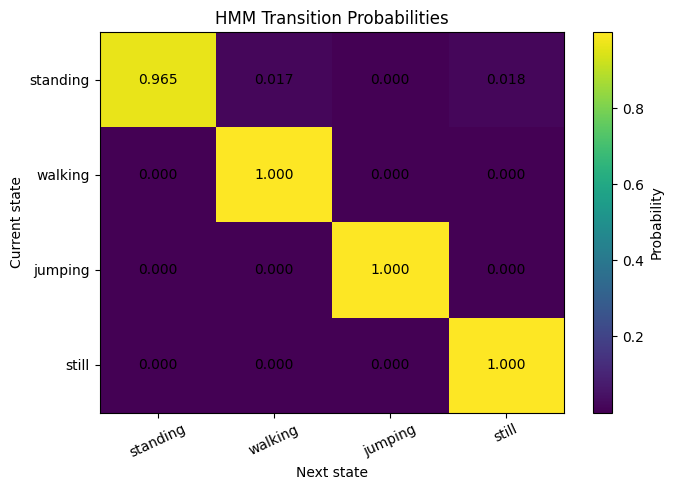

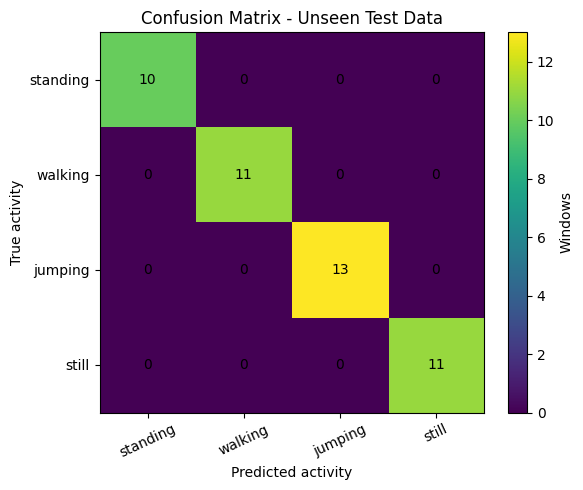

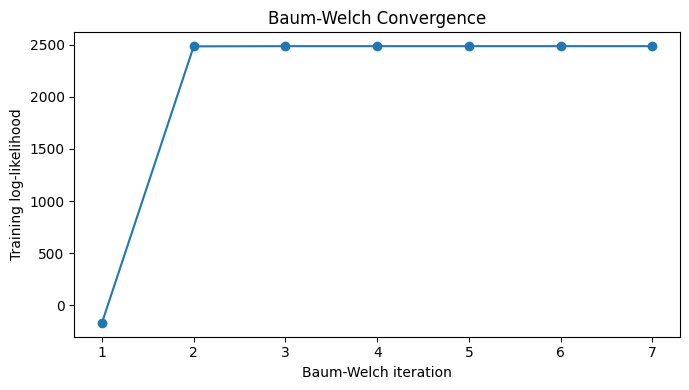

In [5]:
# Save reproducible model parameters, predictions, metrics and figures.
RESULTS = PROJECT_ROOT / "results"
FIGURES = PROJECT_ROOT / "figures"
RESULTS.mkdir(exist_ok=True, parents=True)
FIGURES.mkdir(exist_ok=True, parents=True)

decoded.to_csv(RESULTS / "decoded_test_sequences.csv", index=False)
metrics.to_csv(RESULTS / "evaluation_metrics.csv", index=False)
pd.DataFrame(A, index=states, columns=states).to_csv(RESULTS / "transition_matrix.csv")
pd.DataFrame(means, index=states, columns=features).to_csv(RESULTS / "emission_means_zscore.csv")
pd.DataFrame(variances, index=states, columns=features).to_csv(RESULTS / "emission_variances_zscore.csv")
pd.DataFrame({"state": states, "initial_probability": pi}).to_csv(RESULTS / "initial_state_probabilities.csv", index=False)
pd.DataFrame({"iteration": range(1, len(log_likelihood_history)+1), "log_likelihood": log_likelihood_history}).to_csv(RESULTS / "baum_welch_log_likelihood.csv", index=False)

# Transition matrix heatmap.
fig, ax = plt.subplots(figsize=(7, 5)); im = ax.imshow(A, aspect="auto")
ax.set_xticks(range(K), states, rotation=25); ax.set_yticks(range(K), states)
ax.set_xlabel("Next state"); ax.set_ylabel("Current state"); ax.set_title("HMM Transition Probabilities")
fig.colorbar(im, ax=ax, label="Probability")
for i in range(K):
    for j in range(K): ax.text(j, i, f"{A[i,j]:.3f}", ha="center", va="center")
fig.tight_layout(); fig.savefig(FIGURES / "hmm_transition_probability_heatmap.png", dpi=180); plt.show()

# Confusion matrix and convergence plot.
fig, ax = plt.subplots(figsize=(6, 5)); im = ax.imshow(confusion, aspect="auto")
ax.set_xticks(range(K), states, rotation=25); ax.set_yticks(range(K), states)
ax.set_xlabel("Predicted activity"); ax.set_ylabel("True activity"); ax.set_title("Confusion Matrix - Unseen Test Data")
fig.colorbar(im, ax=ax, label="Windows")
for i in range(K):
    for j in range(K): ax.text(j, i, str(confusion[i,j]), ha="center", va="center")
fig.tight_layout(); fig.savefig(FIGURES / "hmm_confusion_matrix.png", dpi=180); plt.show()

fig, ax = plt.subplots(figsize=(7, 4)); ax.plot(range(1, len(log_likelihood_history)+1), log_likelihood_history, marker="o")
ax.set_xlabel("Baum-Welch iteration"); ax.set_ylabel("Training log-likelihood"); ax.set_title("Baum-Welch Convergence")
fig.tight_layout(); fig.savefig(FIGURES / "hmm_baum_welch_convergence.png", dpi=180); plt.show()


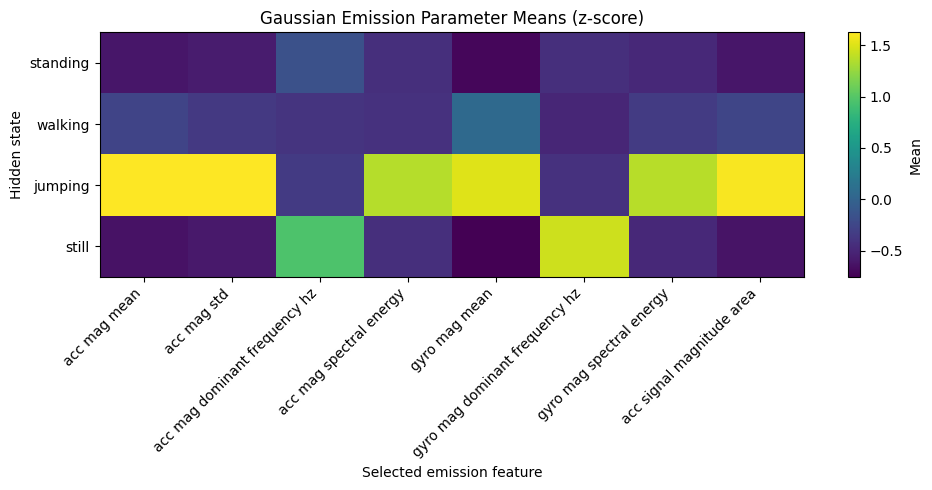

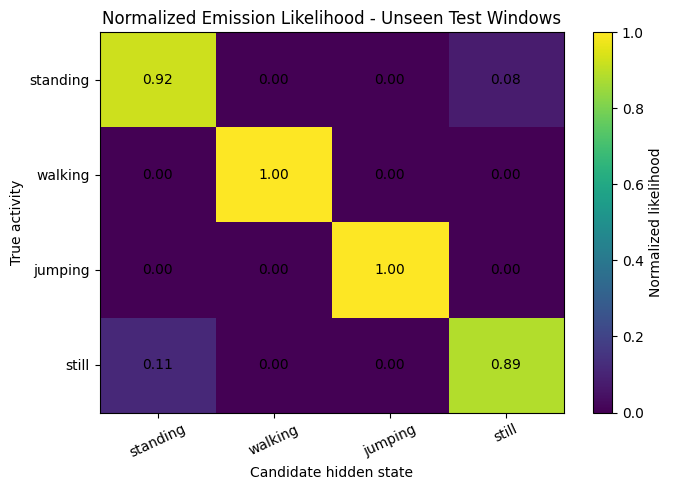

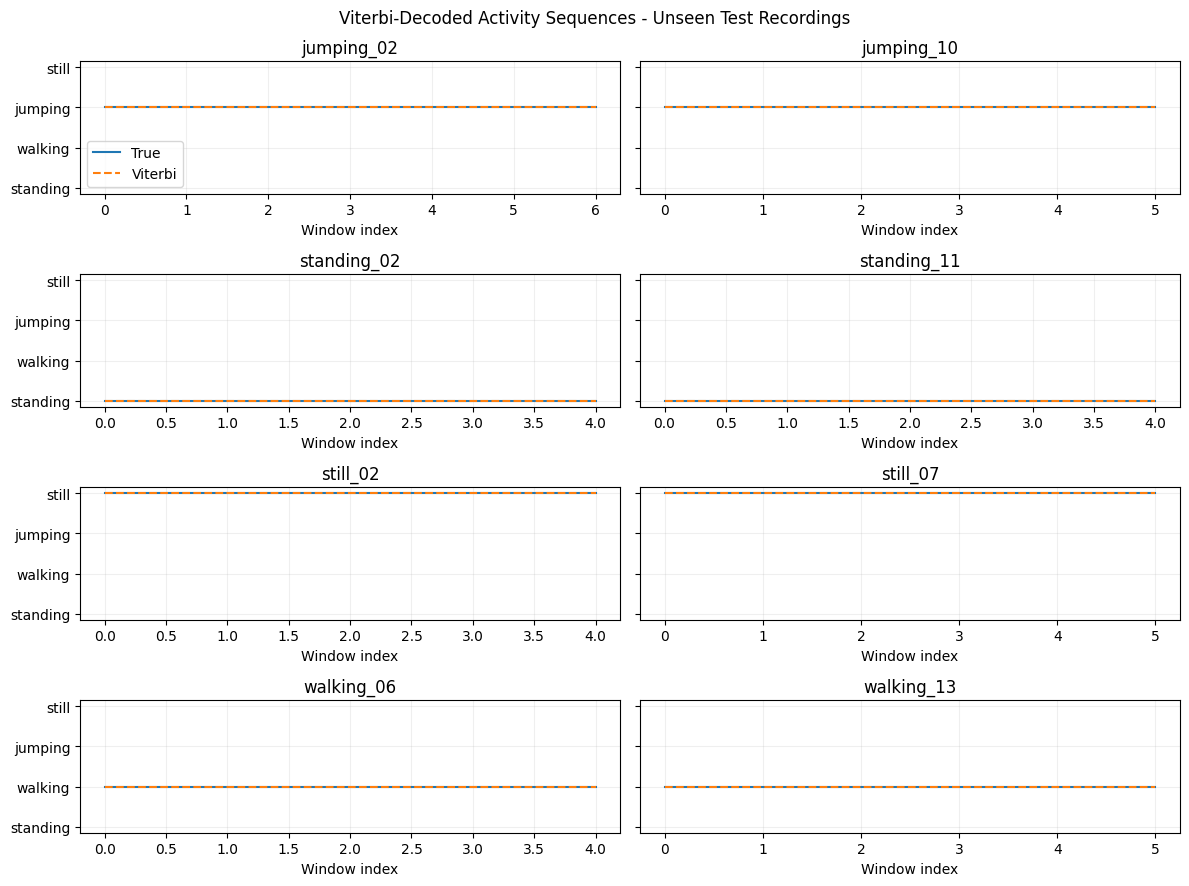

In [6]:
# Emission probability visualization and decoded sequence plot.
# These plots complement the state-transition heatmap and confusion matrix.
selected = ["acc_mag_mean", "acc_mag_std", "acc_mag_dominant_frequency_hz",
            "acc_mag_spectral_energy", "gyro_mag_mean",
            "gyro_mag_dominant_frequency_hz", "gyro_mag_spectral_energy",
            "acc_signal_magnitude_area"]
selected_idx = [features.index(name) for name in selected]
fig, ax = plt.subplots(figsize=(10, 5))
im = ax.imshow(means[:, selected_idx], aspect="auto")
ax.set_xticks(range(len(selected)), [s.replace("_", " ") for s in selected], rotation=45, ha="right")
ax.set_yticks(range(K), states)
ax.set_xlabel("Selected emission feature")
ax.set_ylabel("Hidden state")
ax.set_title("Gaussian Emission Parameter Means (z-score)")
fig.colorbar(im, ax=ax, label="Mean")
fig.tight_layout()
fig.savefig(FIGURES / "hmm_emission_parameter_heatmap.png", dpi=180)
plt.show()

likelihood_rows = []
for _, X, y in test_sequences:
    logp = log_emission(X, means, variances)
    normalized = np.exp(logp - logsumexp(logp, axis=1, keepdims=True))
    for true_label, probs in zip(y, normalized):
        likelihood_rows.append([true_label] + probs.tolist())
likelihood_df = pd.DataFrame(likelihood_rows, columns=["true_activity"] + states)
average_likelihood = likelihood_df.groupby("true_activity")[states].mean().reindex(states)
fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(average_likelihood.values, aspect="auto", vmin=0, vmax=1)
ax.set_xticks(range(K), states, rotation=25)
ax.set_yticks(range(K), states)
ax.set_xlabel("Candidate hidden state")
ax.set_ylabel("True activity")
ax.set_title("Normalized Emission Likelihood - Unseen Test Windows")
fig.colorbar(im, ax=ax, label="Normalized likelihood")
for i in range(K):
    for j in range(K):
        ax.text(j, i, f"{average_likelihood.iloc[i,j]:.2f}", ha="center", va="center")
fig.tight_layout()
fig.savefig(FIGURES / "hmm_emission_probability_heatmap.png", dpi=180)
plt.show()

fig, axes = plt.subplots(4, 2, figsize=(12, 9), sharey=True)
axes = np.ravel(axes)
for ax, (recording_id, group) in zip(axes, decoded.groupby("recording_id", sort=False)):
    true_codes = [state_idx[v] for v in group["true_activity"]]
    predicted_codes = [state_idx[v] for v in group["predicted_activity"]]
    ax.step(range(len(true_codes)), true_codes, where="mid", label="True")
    ax.step(range(len(predicted_codes)), predicted_codes, where="mid", linestyle="--", label="Viterbi")
    ax.set_title(recording_id)
    ax.set_yticks(range(K), states)
    ax.set_xlabel("Window index")
    ax.grid(alpha=0.2)
axes[0].legend()
fig.suptitle("Viterbi-Decoded Activity Sequences - Unseen Test Recordings")
fig.tight_layout()
fig.savefig(FIGURES / "hmm_viterbi_decoded_sequences.png", dpi=180)
plt.show()
